<a href="https://colab.research.google.com/github/abubakkarkk9k-eng/CIFAR-10-Image-Classification-Using-ResNet18/blob/main/CIFAR_10_Image_Classification_Using_ResNet18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **GPU Verification**

### In this step, we verify the availability of a GPU in Google Colab.

### A GPU accelerates deep learning operations by performing parallel computations. We will use PyTorch to check whether CUDA is available and identify the GPU device.

In [59]:
# Import the PyTorch library
import torch

# Display the installed PyTorch version
print("PyTorch Version:", torch.__version__)

# Check whether CUDA is available
gpu_available = torch.cuda.is_available()

print("CUDA Available:", gpu_available)

# Display GPU information if available
if gpu_available:
    gpu_name = torch.cuda.get_device_name(0)

    print("GPU Device:", gpu_name)
    print("GPU Verification Successful!")
else:
    print("GPU is not available. Please enable GPU in Runtime Settings.")

PyTorch Version: 2.14.1+cu130
CUDA Available: True
GPU Device: Tesla T4
GPU Verification Successful!


## **Google Drive Mount**

### In this step, we connect Google Drive with Google Colab.

### Google Drive will be used to store project files, trained model weights, and other important project artifacts.

### Mounting Google Drive allows Colab to access files stored in the user's Drive account.

In [60]:
# Import the Google Drive integration module
from google.colab import drive

# Mount Google Drive to the Colab environment
drive.mount('/content/drive')

# Display a confirmation message
print("Google Drive mounted successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully!


## **CIFAR-10 Dataset Loading**
### In this step, we will download and load the CIFAR-10 dataset using PyTorch. This dataset will provide the images our CNN model will learn to classify.

### CIFAR-10 contains:
### >50,000 training images.
### >10,000 testing images.
### >10 different image classes.
### >Image dimensions of 32 × 32 pixels.
### >Three RGB color channels.




### **Import Required Libraries**
### First, we import the required PyTorch libraries. torchvision provides the CIFAR-10 dataset and image transformations, while DataLoader helps load images in batches.

In [61]:
# Import the PyTorch library
import torch

# Import the DataLoader utility
from torch.utils.data import DataLoader

# Import CIFAR-10 dataset and image transformations
from torchvision import datasets, transforms

# Import Matplotlib for image visualization
import matplotlib.pyplot as plt

# Display a confirmation message
print("Libraries imported successfully!")

Libraries imported successfully!


### **Define Image Transformations**
### Explanation: Deep learning models work with numerical data rather than raw images. We use ToTensor() to convert images into PyTorch tensors and Normalize() to scale pixel values into a range suitable for model training.

In [62]:
# Define image preprocessing transformations
transform = transforms.Compose([
    # Convert images into PyTorch tensors
    transforms.ToTensor(),

    # Normalize RGB channels
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

# Display a confirmation message
print("Image transformations defined successfully!")

Image transformations defined successfully!


## **Load the Training Dataset**
### Explanation: Here, we download the CIFAR-10 training dataset. The training dataset contains 50,000 images that our CNN model will use to learn image patterns.

In [63]:
# Define the dataset storage directory
data_directory = "./data"

# Download and load the CIFAR-10 training dataset
train_dataset = datasets.CIFAR10(
    root=data_directory,
    train=True,
    download=True,
    transform=transform
)

# Display the training dataset size
print("Training Dataset Size:", len(train_dataset))

Training Dataset Size: 50000


## **Load the Testing Dataset**
### The testing dataset contains 10,000 separate images. We will use these images after training to evaluate how well our model classifies images it has not trained on.

In [64]:
# Download and load the CIFAR-10 testing dataset
test_dataset = datasets.CIFAR10(
    root=data_directory,
    train=False,
    download=True,
    transform=transform
)

# Display the testing dataset size
print("Testing Dataset Size:", len(test_dataset))

Testing Dataset Size: 10000


## **Define Dataset Classes**
### CIFAR-10 contains ten image categories. We retrieve their names so that we can understand the labels associated with the images.

In [65]:
# Retrieve the class names from the training dataset
class_names = train_dataset.classes

# Display all available classes
print("CIFAR-10 Classes:")

for index, class_name in enumerate(class_names):
    print(index, "-", class_name)

CIFAR-10 Classes:
0 - airplane
1 - automobile
2 - bird
3 - cat
4 - deer
5 - dog
6 - frog
7 - horse
8 - ship
9 - truck


## **Create DataLoaders**
### A DataLoader divides the dataset into smaller batches. We will use a batch size of 64, meaning the model will process 64 images in one training iteration. We shuffle training data to improve learning, while testing data remains in a fixed order.

In [66]:
# Create the training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

# Create the testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

# Display DataLoader information
print("Training Batches:", len(train_loader))
print("Testing Batches:", len(test_loader))

print("DataLoaders created successfully!")

Training Batches: 782
Testing Batches: 157
DataLoaders created successfully!


## **Inspect One Batch**
### Now we retrieve one batch from the training DataLoader. We check the dimensions of the images and labels to make sure our dataset is correctly prepared for the CNN model.

In [67]:
# Retrieve one batch of training images and labels
images, labels = next(iter(train_loader))

# Display the image tensor dimensions
print("Image Batch Shape:", images.shape)

# Display the label tensor dimensions
print("Label Batch Shape:", labels.shape)

# Display the first five labels
print("First Five Labels:", labels[:5])

Image Batch Shape: torch.Size([64, 3, 32, 32])
Label Batch Shape: torch.Size([64])
First Five Labels: tensor([8, 2, 2, 0, 6])


## **Visualize Sample Images**
### We display a few dataset images to understand what our model will classify. We reverse the normalization before displaying the images so their original colors appear correctly.

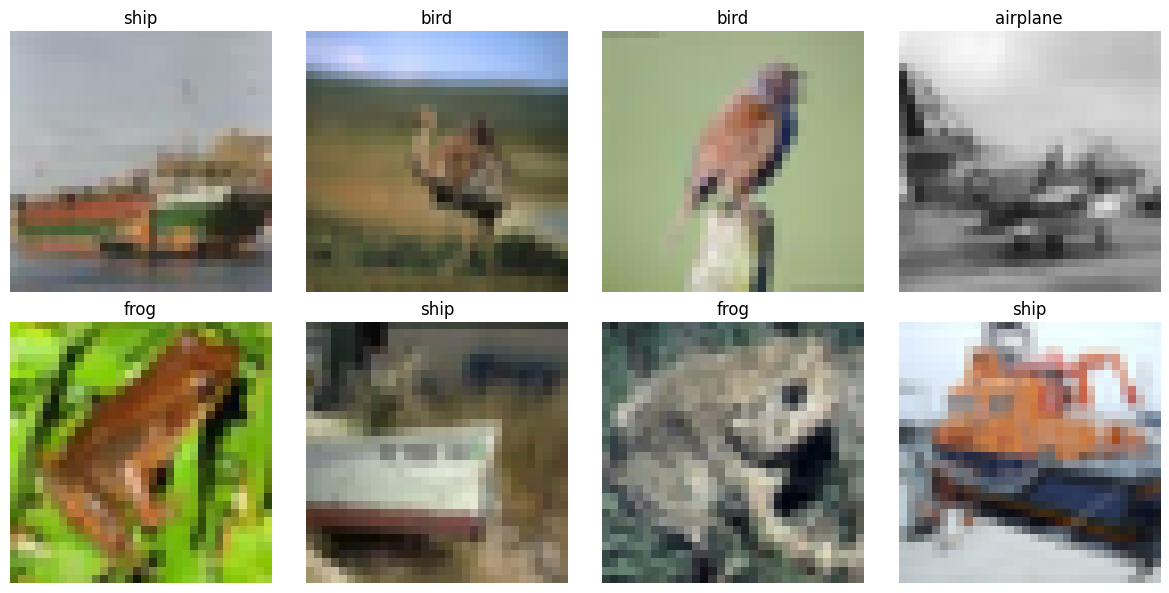

In [68]:
# Create a figure for displaying sample images
plt.figure(figsize=(12, 6))

# Display the first eight images
for index in range(8):

    # Select one image from the batch
    image = images[index]

    # Reverse normalization for visualization
    image = image * 0.5 + 0.5

    # Rearrange image dimensions for Matplotlib
    image = image.permute(1, 2, 0)

    # Create a subplot
    plt.subplot(2, 4, index + 1)

    # Display the image
    plt.imshow(image)

    # Display the corresponding class name
    plt.title(class_names[labels[index].item()])

    # Hide axis labels
    plt.axis("off")

# Adjust the layout
plt.tight_layout()

# Display the images
plt.show()

# **MLflow Setup**
### We will configure MLflow to track our deep learning experiments.

### MLflow will help us record:
### - Model parameters (learning rate, batch size, epochs).
### - Training and testing accuracy.
### - Training and testing loss.
### - Experiment results.

### **Install MLflow**
### MLflow is an experiment-tracking library. We first install it in our Google Colab environment so that we can use its tracking features.

In [69]:
%pip install mlflow -q

### **Import MLflow**

### In this step, we import MLflow and check its installed version. This confirms that MLflow is available in our Python environment.

In [70]:
# Import the MLflow library
import mlflow

# Display the installed MLflow version
print("MLflow Version:", mlflow.__version__)

MLflow Version: 3.18.0


### **Create an MLflow Tracking Directory**
###We will create a dedicated folder in Google Drive to store our MLflow experiment records. This helps preserve experiment information even after the Colab session ends.

In [71]:
# Import the operating system module
import os

# Define the MLflow tracking directory
mlflow_directory = "/content/drive/MyDrive/CIFAR10_MLflow/mlruns"

# Create the directory if it does not exist
os.makedirs(mlflow_directory, exist_ok=True)

# Display the directory location
print("MLflow Tracking Directory:", mlflow_directory)
print("Directory created successfully!")

MLflow Tracking Directory: /content/drive/MyDrive/CIFAR10_MLflow/mlruns
Directory created successfully!


### **Configure MLflow Tracking**
### In this cell, we connect MLflow to the tracking directory created in Google Drive. This tells MLflow where to save experiment information, including parameters, metrics, and results.

In [72]:
# Configure the MLflow tracking location
mlflow.set_tracking_uri(
    "file:///content/drive/MyDrive/CIFAR10_MLflow/mlruns"
)

# Display the tracking location
print("MLflow Tracking URI:", mlflow.get_tracking_uri())
print("MLflow tracking configured successfully!")

MLflow Tracking URI: file:///content/drive/MyDrive/CIFAR10_MLflow/mlruns
MLflow tracking configured successfully!


## **Create an MLflow Experiment**
### Explanation: An experiment is a workspace in MLflow where we organize and track our model training runs. We will create an experiment named CIFAR10_Image_Classification.

### This experiment will store the training parameters, accuracy, and loss of our CNN model.

In [73]:
# Import the operating system module to configure environment variables
import os

# Enable the filesystem tracking backend in MLflow 3.x
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

# Define the experiment name
experiment_name = "CIFAR10_Image_Classification"

# Create or select the MLflow experiment
mlflow.set_experiment(experiment_name)

# Display the experiment name
print("Experiment Name:", experiment_name)
print("MLflow experiment created successfully!")

Experiment Name: CIFAR10_Image_Classification
MLflow experiment created successfully!


# **Transfer Learning Using Pretrained ResNet18**

### In this section, we use Transfer Learning to improve our CIFAR-10 image classification model. We use the pretrained ResNet18 architecture, which has already learned useful image features from the ImageNet dataset. Instead of training the entire model from scratch, we adapt its final classification layer to recognize the 10 classes of CIFAR-10. This approach allows us to reuse previously learned visual features and train an efficient image classification model.

## **Prepare Images for ResNet18**
###ResNet18 was pretrained on ImageNet. Its standard input size is 224 × 224 pixels, and it uses ImageNet normalization values. Therefore, we must update our image transformations and recreate the CIFAR-10 DataLoaders.

In [74]:
# Define ImageNet preprocessing transformations
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

# Reload the CIFAR-10 training dataset
train_dataset = datasets.CIFAR10(
    root=data_directory,
    train=True,
    download=False,
    transform=transform
)

# Reload the CIFAR-10 testing dataset
test_dataset = datasets.CIFAR10(
    root=data_directory,
    train=False,
    download=False,
    transform=transform
)

# Recreate the training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

# Recreate the testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

# Display dataset information
print("Training Dataset Size:", len(train_dataset))
print("Testing Dataset Size:", len(test_dataset))
print("Image Transformations Updated Successfully!")

Training Dataset Size: 50000
Testing Dataset Size: 10000
Image Transformations Updated Successfully!


## **Load the Pretrained ResNet18 Model**
### We import ResNet18 from torchvision.models and load its pretrained ImageNet weights.

### These weights allow our model to start with previously learned visual features instead of learning everything from random initialization.

In [75]:
# Import PyTorch neural network modules
import torch.nn as nn
import torch.optim as optim

# Import ResNet18 and its pretrained weights
from torchvision.models import resnet18, ResNet18_Weights

# Load ResNet18 with pretrained ImageNet weights
model = resnet18(weights=ResNet18_Weights.DEFAULT)

# Display a confirmation message
print("Pretrained ResNet18 Model Loaded Successfully!")

Pretrained ResNet18 Model Loaded Successfully!


## **Replace the Final Classification Layer**
###ResNet18 was originally trained to classify 1,000 ImageNet categories. However, our CIFAR-10 dataset contains only 10 classes.

### We will replace the final fully connected layer with a new layer containing 10 output neurons. The pretrained feature-extraction layers will remain available for our task.

In [76]:
# Get the number of input features in the final layer
input_features = model.fc.in_features

# Replace the final classification layer
model.fc = nn.Linear(input_features, 10)

# Display the updated output layer
print("Updated Classification Layer:", model.fc)
print("Number of Output Classes:", 10)

Updated Classification Layer: Linear(in_features=512, out_features=10, bias=True)
Number of Output Classes: 10


## **Freeze Pretrained Layers**
###In transfer learning, freezing layers means preventing their weights from changing during training.

### We will freeze the pretrained ResNet18 layers and keep only the new final classification layer trainable. This allows the model to reuse ImageNet features while learning to classify CIFAR-10 images.

In [77]:
# Freeze all pretrained model parameters
for parameter in model.parameters():
    parameter.requires_grad = False

# Unfreeze the final classification layer
for parameter in model.fc.parameters():
    parameter.requires_grad = True

# Display a confirmation message
print("Pretrained Layers Frozen Successfully!")
print("Final Classification Layer Remains Trainable!")

Pretrained Layers Frozen Successfully!
Final Classification Layer Remains Trainable!


### **Move ResNet18 to GPU**
### In this cell, we move our updated ResNet18 model to the available computing device. Since we have a Tesla T4 GPU in Google Colab, the model will run on the GPU to accelerate training.

In [78]:
# Select the available computing device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Move the ResNet18 model to the selected device
model = model.to(device)

# Display device information
print("Computing Device:", device)
print("ResNet18 Model Moved Successfully!")

Computing Device: cuda
ResNet18 Model Moved Successfully!


## **Display Trainable Parameters**
### In this cell, we calculate the number of trainable parameters in our ResNet18 model.

### Because we froze the pretrained layers, only the new final classification layer should contain trainable parameters. This verifies that transfer learning has been configured correctly.

In [79]:
# Calculate the number of trainable parameters
trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

# Calculate the total number of model parameters
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

# Display parameter information
print("Total Model Parameters:", total_parameters)
print("Trainable Parameters:", trainable_parameters)
print("Frozen Parameters:", total_parameters - trainable_parameters)

Total Model Parameters: 11181642
Trainable Parameters: 5130
Frozen Parameters: 11176512


# **Model Training**
### Objective: Now we will train our pretrained ResNet18 model using the CIFAR-10 training dataset.

### During training, the model will learn to classify images into 10 categories by updating its new classification layer.

## **Define the Loss Function**
###We use CrossEntropyLoss because our project involves classifying images into 10 different categories. It measures the difference between the model's predictions and the actual image labels.

In [80]:
# Define the classification loss function
criterion = nn.CrossEntropyLoss()

# Display a confirmation message
print("Cross Entropy Loss Function Defined Successfully!")

Cross Entropy Loss Function Defined Successfully!


## **Define the Optimizer**
###We will use the Adam optimizer to update the trainable parameters of our ResNet18 model.

### The learning rate controls how much the model updates its weights during training. We will start with 0.001, which is a reasonable starting value for training the new classification layer.

### Since we froze the pretrained layers in Step 5, the optimizer will update only the final classification layer.

In [81]:
# Define the Adam optimizer
optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

# Display optimizer information
print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Optimizer Defined Successfully!")

Optimizer: Adam
Learning Rate: 0.001
Optimizer Defined Successfully!


## **Define Training Parameters**
### We define the training configuration for our ResNet18 model.
### - num_epochs = 5: The model will process the complete training dataset five times.
### - batch_size = 64: Each training batch contains 64 images.
### - learning_rate = 0.001: This is the learning rate used by the Adam optimizer.
### We will begin with five epochs as an initial experiment. We can evaluate the results before deciding whether more training is needed.

In [82]:
# Define the number of training epochs
num_epochs = 5

# Define the batch size
batch_size = 64

# Define the learning rate
learning_rate = 0.001

# Display training configuration
print("Training Configuration")
print("----------------------")
print("Epochs:", num_epochs)
print("Batch Size:", batch_size)
print("Learning Rate:", learning_rate)

Training Configuration
----------------------
Epochs: 5
Batch Size: 64
Learning Rate: 0.001


## **Train the ResNet18 Model**

### During training, the model processes batches of CIFAR-10 images, generates predictions, calculates loss, and updates the final classification layer using backpropagation and the Adam optimizer.

### We will also use MLflow to record training loss and accuracy after each epoch.

### Because we are using feature extraction, we keep the pretrained backbone in evaluation mode so its Batch Normalization statistics remain unchanged. The new classification layer will still learn through gradient updates.

In [83]:
# Initialize lists to store training results
training_losses = []
training_accuracies = []

# Start an MLflow experiment run
with mlflow.start_run(run_name="ResNet18_CIFAR10_Feature_Extraction"):

    # Log training parameters
    mlflow.log_param("model", "ResNet18")
    mlflow.log_param("pretrained_weights", "ImageNet")
    mlflow.log_param("epochs", num_epochs)
    mlflow.log_param("batch_size", batch_size)
    mlflow.log_param("learning_rate", learning_rate)

    # Keep pretrained layers in evaluation mode
    model.eval()

    # Set the final classification layer to training mode
    model.fc.train()

    # Start the training process
    for epoch in range(num_epochs):

        running_loss = 0.0
        correct_predictions = 0
        total_predictions = 0

        # Process each training batch
        for images, labels in train_loader:

            # Move images and labels to the GPU
            images = images.to(device)
            labels = labels.to(device)

            # Clear previous gradients
            optimizer.zero_grad()

            # Generate model predictions
            outputs = model(images)

            # Calculate classification loss
            loss = criterion(outputs, labels)

            # Perform backpropagation
            loss.backward()

            # Update trainable parameters
            optimizer.step()

            # Calculate batch loss
            running_loss += loss.item()

            # Calculate correct predictions
            _, predicted = torch.max(outputs.data, 1)

            total_predictions += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

        # Calculate epoch loss and accuracy
        epoch_loss = running_loss / len(train_loader)
        epoch_accuracy = 100 * correct_predictions / total_predictions

        # Store training results
        training_losses.append(epoch_loss)
        training_accuracies.append(epoch_accuracy)

        # Record metrics in MLflow
        mlflow.log_metric("training_loss", epoch_loss, step=epoch + 1)
        mlflow.log_metric("training_accuracy", epoch_accuracy, step=epoch + 1)

        # Display epoch results
        print(f"Epoch [{epoch + 1}/{num_epochs}]")
        print(f"Training Loss: {epoch_loss:.4f}")
        print(f"Training Accuracy: {epoch_accuracy:.2f}%")
        print("------------------------------")

print("Model Training Completed Successfully!")

Epoch [1/5]
Training Loss: 0.5625
Training Accuracy: 82.42%
------------------------------
Epoch [2/5]
Training Loss: 0.3803
Training Accuracy: 87.02%
------------------------------
Epoch [3/5]
Training Loss: 0.3544
Training Accuracy: 87.70%
------------------------------
Epoch [4/5]
Training Loss: 0.3413
Training Accuracy: 88.17%
------------------------------
Epoch [5/5]
Training Loss: 0.3342
Training Accuracy: 88.55%
------------------------------
Model Training Completed Successfully!


# **Model Evaluation and Accuracy**
### Objective: We will evaluate our trained ResNet18 model using the 10,000 CIFAR-10 testing images.

### The testing dataset contains images that were not used during training. This helps us measure how well our model performs on unseen images.

## **Evaluate the Trained Model**
### We calculate the model's testing loss and testing accuracy.

### We use model.eval() to switch the model into evaluation mode and torch.no_grad() to prevent gradient calculations during testing. We will also record the evaluation results in MLflow.

In [84]:
# Set the model to evaluation mode
model.eval()

# Initialize evaluation variables
test_loss = 0.0
correct_predictions = 0
total_predictions = 0

# Disable gradient calculations during evaluation
with torch.no_grad():

    # Process the testing dataset
    for images, labels in test_loader:

        # Move images and labels to the selected device
        images = images.to(device)
        labels = labels.to(device)

        # Generate model predictions
        outputs = model(images)

        # Calculate the testing loss
        loss = criterion(outputs, labels)

        # Accumulate the total testing loss
        test_loss += loss.item() * labels.size(0)

        # Get the predicted class
        _, predicted = torch.max(outputs, 1)

        # Count correct predictions
        total_predictions += labels.size(0)
        correct_predictions += (predicted == labels).sum().item()

# Calculate average testing loss
average_test_loss = test_loss / total_predictions

# Calculate testing accuracy
test_accuracy = 100 * correct_predictions / total_predictions

# Record evaluation results in MLflow
with mlflow.start_run(run_name="ResNet18_CIFAR10_Evaluation"):
    mlflow.log_metric("test_loss", average_test_loss)
    mlflow.log_metric("test_accuracy", test_accuracy)

# Display evaluation results
print("Testing Loss:", round(average_test_loss, 4))
print("Correct Predictions:", correct_predictions)
print("Total Testing Images:", total_predictions)
print("Testing Accuracy:", round(test_accuracy, 2), "%")

Testing Loss: 0.3794
Correct Predictions: 8694
Total Testing Images: 10000
Testing Accuracy: 86.94 %


### **Calculate Class-Wise Accuracy**
### Overall accuracy tells us how well the model performs across all ten classes. However, it does not show which individual classes the model recognizes correctly.

### We calculate accuracy separately for each CIFAR-10 category, such as airplane, automobile, cat, and dog. This helps us identify the classes where our model performs well or struggles.

In [85]:
# Set the model to evaluation mode
model.eval()

# Initialize class-wise prediction counters
class_correct = [0] * len(class_names)
class_total = [0] * len(class_names)

# Disable gradient calculations
with torch.no_grad():

    # Process the testing dataset
    for images, labels in test_loader:

        # Move images and labels to the selected device
        images = images.to(device)
        labels = labels.to(device)

        # Generate model predictions
        outputs = model(images)

        # Get predicted class indices
        _, predicted = torch.max(outputs, 1)

        # Calculate class-wise correct predictions
        for index in range(labels.size(0)):

            label = labels[index].item()
            prediction = predicted[index].item()

            class_total[label] += 1

            if prediction == label:
                class_correct[label] += 1

# Display accuracy for each class
print("Class-Wise Testing Accuracy")
print("---------------------------")

for index, class_name in enumerate(class_names):

    accuracy = (
        100 * class_correct[index] / class_total[index]
    )

    print(f"{class_name}: {accuracy:.2f}%")

Class-Wise Testing Accuracy
---------------------------
airplane: 92.00%
automobile: 93.50%
bird: 77.80%
cat: 79.00%
deer: 88.70%
dog: 81.60%
frog: 91.80%
horse: 86.20%
ship: 90.20%
truck: 88.60%


# **Generate the Confusion Matrix**
### A confusion matrix is an evaluation tool used to analyze classification performance. It compares the actual image labels with the model's predicted labels.
### - Rows represent actual classes.
### - Columns represent predicted classes.
### - Diagonal values represent correct predictions.
### - Values outside the diagonal represent incorrect predictions.
### This helps us understand which image categories our ResNet18 model confuses with one another.

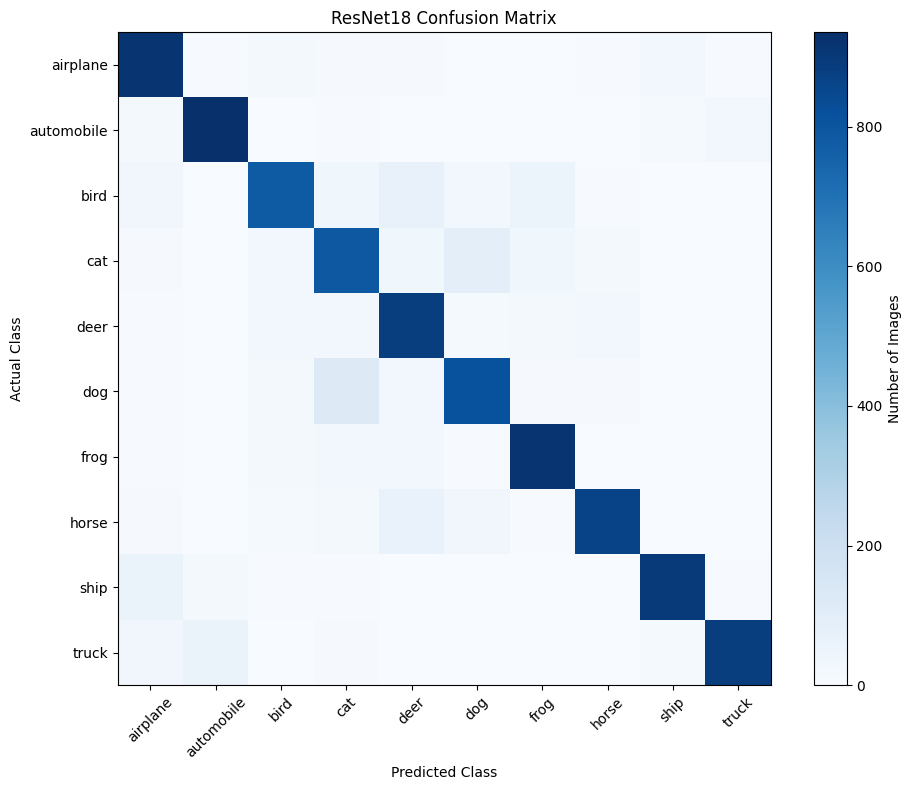

In [86]:
# Set the model to evaluation mode
model.eval()

# Initialize a confusion matrix
confusion_matrix = torch.zeros(
    10, 10,
    dtype=torch.int64
)

# Disable gradient calculations
with torch.no_grad():

    # Process the testing dataset
    for images, labels in test_loader:

        # Move images and labels to the selected device
        images = images.to(device)
        labels = labels.to(device)

        # Generate model predictions
        outputs = model(images)

        # Get predicted class indices
        _, predicted = torch.max(outputs, 1)

        # Calculate confusion matrix values for the batch
        batch_matrix = torch.bincount(
            (labels * 10 + predicted).cpu(),
            minlength=100
        ).reshape(10, 10)

        # Accumulate batch results
        confusion_matrix += batch_matrix

# Display the confusion matrix
plt.figure(figsize=(10, 8))

plt.imshow(confusion_matrix.numpy(), cmap="Blues")

plt.title("ResNet18 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)

plt.colorbar(label="Number of Images")
plt.tight_layout()
plt.show()

# **Save the Best ResNet18 Model**
### We create a model checkpoint containing the best model's weights and important evaluation information. We then save this checkpoint to our Google Drive project directory using PyTorch's torch.save() function.

In [87]:
# Import the operating system module
import os

# Define the best model file location
best_model_path = (
    "/content/drive/MyDrive/CIFAR10_MLflow/"
    "best_resnet18_cifar10.pth"
)

# Create the project directory if it does not exist
os.makedirs(os.path.dirname(best_model_path), exist_ok=True)

# Prepare the best model checkpoint using current model weights
best_model_checkpoint = {
    "model_name": "ResNet18",
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "epoch": num_epochs,
    "test_accuracy": test_accuracy,
    "test_loss": average_test_loss
}

# Save the model checkpoint
torch.save(best_model_checkpoint, best_model_path)

# Display confirmation information
print("Model Saved Successfully!")
print("Model Name: ResNet18")
print("Total Epochs:", num_epochs)

print(
    "Final Testing Accuracy:",
    round(test_accuracy, 2), "%"
)

print("Saved Location:", best_model_path)

Model Saved Successfully!
Model Name: ResNet18
Total Epochs: 5
Final Testing Accuracy: 86.94 %
Saved Location: /content/drive/MyDrive/CIFAR10_MLflow/best_resnet18_cifar10.pth


## **Verify the Saved Best Model**
### We verify that the best model checkpoint has been successfully saved in Google Drive. We also check the file name and file size to confirm that the checkpoint exists.

In [88]:
# Check whether the best model file exists
if os.path.exists(best_model_path):

    # Calculate the model file size in megabytes
    file_size = os.path.getsize(best_model_path) / (1024 * 1024)

    # Display verification information
    print("Best Model Verified Successfully!")
    print("File Name:", os.path.basename(best_model_path))
    print("File Size:", round(file_size, 2), "MB")
    print("Model Location:", best_model_path)

else:
    print("Best model file was not found!")

Best Model Verified Successfully!
File Name: best_resnet18_cifar10.pth
File Size: 42.73 MB
Model Location: /content/drive/MyDrive/CIFAR10_MLflow/best_resnet18_cifar10.pth
